# RQ11 — Binary subtype recognition versus multiclass functional discrimination

## Scientific question

**How does the formulation of phage lytic-function prediction as independent subtype-vs-background binary tasks versus mutually exclusive multiclass discrimination alter apparent performance, robustness, representation dependence, and the biological errors made by the models?**

This RQ compares two distinct biological learning problems:

### Binary subtype recognition

Each subtype is learned independently against the frozen non-lytic background:

- `subtype_endolysin`
- `subtype_depolymerase`
- `subtype_val`

Other lytic subtypes are excluded from the negative class.

### Clean multiclass discrimination

`multiclass_clean`

The model must discriminate among:

- endolysin;
- depolymerase;
- virion-associated lytic enzyme (VAL).

Ambiguous / multiple-nonexclusive lytic proteins are excluded from the clean multiclass benchmark.

RQ11 therefore asks what changes when the model moves from:

> **“Is this protein compatible with subtype X?”**

to:

> **“Which one of these mutually exclusive clean lytic functions best describes this protein?”**

## Core methodological rule

Binary and multiclass tasks do **not** automatically evaluate the same entity sets and are not entity-level paired experiments.

All direct binary-versus-multiclass deltas in RQ11 are therefore:

> **matched-factor formulation contrasts**

where `R`, `S`, representation, and algorithm are held constant.

They are **not paired sequence-level effects**.

The most comparable quantities are class-specific:

- binary positive-class F1 / recall / precision;
- multiclass per-class F1 / recall / precision.

Global binary MCC and global multiclass MCC remain useful for within-formulation summaries but are not interpreted as directly equivalent class-specific quantities.

## What RQ11 should establish

1. Does class-specific performance change when subtype detection becomes subtype discrimination?
2. Is the formulation effect similar for endolysin, depolymerase, and VAL?
3. Do R and S affect binary and multiclass formulations differently?
4. Does representation quality mitigate or amplify the formulation shift?
5. Does increased PLM capacity (T6→T30) help equally in both formulations?
6. Does downstream classifier choice matter more in one formulation?
7. Do model rankings transfer from binary to multiclass tasks?
8. Which subtype confusions dominate the multiclass problem?
9. Can strong aggregate multiclass performance conceal poor resolution of a specific class?
10. Is VAL uniquely affected because the multiclass requirement combines discrimination with Low-N evidence?

## Interpretation guardrails

- A lower multiclass per-class F1 does not mean the multiclass model is “worse”; it solves a different problem.
- A binary positive prediction indicates subtype compatibility relative to non-lytic background, not exclusivity among lytic functions.
- Multiclass imposes competition among lytic classes.
- Clean multiclass explicitly removes multiple/nonexclusive labels; conclusions apply only to the clean mutually exclusive subset.
- VAL conclusions remain support-aware because RQ10 established severe Low-N.
- Native R/S contrasts remain nonpaired across cells.
- No bootstrap here; finite-test uncertainty belongs to RQ17.
- No common-test R/S decomposition here; that belongs to RQ16.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 400)
pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 400)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

BINARY_TASKS = {
    "endolysin": "subtype_endolysin",
    "depolymerase": "subtype_depolymerase",
    "val": "subtype_val",
}

MULTI_TASK = "multiclass_clean"

SUBTYPE_ORDER = [
    "endolysin",
    "depolymerase",
    "val",
]

SUBTYPE_LABELS = {
    "endolysin": "Endolysin",
    "depolymerase": "Depolymerase",
    "val": "VAL",
}

TASK_PATHS = {
    "subtype_endolysin": "subtype_binary/endolysin",
    "subtype_depolymerase": "subtype_binary/depolymerase",
    "subtype_val": "subtype_binary/virion_associated_lytic_enzyme",
    "multiclass_clean": "multiclass_clean",
}

T6 = "esm2_t6_8m"
T30 = "esm2_t30_150m"
ONEHOT = "onehot_1024"
ROXY = "roxy_48"

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/training_supervised").is_dir()
            and (candidate / "data/predictive_universe").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate project root containing Stage12A, "
        "training_supervised, and predictive_universe."
    )

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
TRAINING_ROOT = ROOT / "results/training_supervised"
PREDICTIVE_ROOT = ROOT / "data/predictive_universe"
CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass


# 1. Load supervised master and per-class metrics

In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

per_class_path = STAGE12A / "per_class_results.tsv"
if not per_class_path.is_file():
    raise FileNotFoundError(per_class_path)

per_class = pd.read_csv(
    per_class_path,
    sep="\t",
    low_memory=False,
)

binary_master = master[
    master["task"].isin(BINARY_TASKS.values())
].copy()

multi_master = master[
    master["task"].eq(MULTI_TASK)
].copy()

REPS = sorted(binary_master["representation"].unique())
ALGORITHMS = sorted(binary_master["algorithm"].unique())

print("Binary subtype families:", len(binary_master))
print("Multiclass families:", len(multi_master))
print("Representations:", REPS)
print("Algorithms:", ALGORITHMS)

expected_binary = 3 * 16 * len(REPS) * len(ALGORITHMS)
expected_multi = 16 * len(REPS) * len(ALGORITHMS)

assert len(binary_master) == expected_binary
assert len(multi_master) == expected_multi

display(
    binary_master.groupby("task").size().rename("n_families")
)

Binary subtype families: 960
Multiclass families: 320
Representations: ['esm2_t30_150m', 'esm2_t6_8m', 'onehot_1024', 'roxy_48']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']


task
subtype_depolymerase    320
subtype_endolysin       320
subtype_val             320
Name: n_families, dtype: int64

In [3]:
print("Master columns:")
print(list(master.columns))

print("\nPer-class columns:")
print(list(per_class.columns))

print("\nPer-class multiclass rows:", len(per_class[per_class["task"].eq(MULTI_TASK)]))

Master columns:
['experiment_id', 'task', 'task_type', 'R', 'S', 'representation', 'algorithm', 'selected_config', 'mcc', 'ap', 'ap_baseline', 'ap_gain', 'roc_auc', 'f1', 'precision', 'recall', 'specificity', 'balanced_accuracy', 'brier', 'log_loss', 'threshold', 'prevalence', 'predicted_positive_fraction', 'tp', 'tn', 'fp', 'fn', 'n', 'n_positive', 'n_negative', 'runtime__experiment_id', 'runtime__validation_and_final_wall_seconds', 'runtime__final_fit_seconds', 'runtime__final_test_prediction_seconds', 'runtime__process_peak_rss_kb_start', 'runtime__process_peak_rss_kb_end', 'runtime__representation_dimension', 'runtime__representation_sparse', 'runtime__n_outer_train', 'runtime__n_inner_train', 'runtime__n_validation', 'runtime__n_outer_test', 'macro_f1', 'macro_precision', 'macro_recall', 'weighted_f1']

Per-class columns:
['experiment_id', 'task', 'R', 'S', 'representation', 'algorithm', 'class_id', 'class_name', 'support', 'precision', 'recall', 'f1']

Per-class multiclass rows: 

# 2. Robust subtype canonicalization for multiclass per-class results

In [4]:
def normalize_class_text(series):
    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .str.replace("-", "_", regex=False)
        .str.replace(" ", "_", regex=False)
        .str.replace("/", "_", regex=False)
    )

def canonical_subtype_from_text(value):
    s = str(value).strip().lower()
    s = s.replace("-", "_").replace(" ", "_").replace("/", "_")

    if "depoly" in s or s in {"dpo", "depolymerase"}:
        return "depolymerase"

    if (
        "virion" in s
        or "associated_lytic" in s
        or s in {"val", "virion_associated_lytic_enzyme"}
    ):
        return "val"

    if "endolysin" in s or s in {"endo", "endolysin"}:
        return "endolysin"

    return None

class_col = next(
    (
        c for c in [
            "class_name",
            "class",
            "target_class",
            "label_name",
            "label",
        ]
        if c in per_class.columns
    ),
    None,
)

if class_col is None:
    raise KeyError(
        "Could not identify a class column in per_class_results.tsv"
    )

multi_pc = per_class[
    per_class["task"].eq(MULTI_TASK)
].copy()

multi_pc["subtype"] = (
    multi_pc[class_col]
    .map(canonical_subtype_from_text)
)

print("Initial subtype mapping:")
display(
    multi_pc[
        [class_col, "subtype"]
    ]
    .drop_duplicates()
    .sort_values(class_col)
)

Initial subtype mapping:


,class_name,subtype
3840,depolymerase,depolymerase
3841,endolysin,endolysin
3842,virion_associated_lytic_enzyme,val


If the per-class table uses numeric class IDs, the next block reconstructs the numeric-label → biological-class mapping from the frozen multiclass eligible entities.

In [5]:
def infer_split_column(df):
    for c in ["split", "outer_split", "partition", "set"]:
        if c in df.columns:
            return c
    raise KeyError(
        f"No split column found. Available columns: {list(df.columns)}"
    )

def candidate_eligible_paths(task, r, s):
    aliases = {
        "subtype_endolysin": [
            "subtype_endolysin",
            "subtype_binary/endolysin",
        ],
        "subtype_depolymerase": [
            "subtype_depolymerase",
            "subtype_binary/depolymerase",
        ],
        "subtype_val": [
            "subtype_val",
            "subtype_binary/virion_associated_lytic_enzyme",
        ],
        "multiclass_clean": [
            "multiclass_clean",
        ],
    }

    return [
        PREDICTIVE_ROOT
        / alias
        / f"R{r}_S{s}"
        / "eligible_entities.tsv.gz"
        for alias in aliases[task]
    ]

def resolve_eligible_path(task, r, s):
    for p in candidate_eligible_paths(task, r, s):
        if p.is_file():
            return p
    raise FileNotFoundError(
        f"No eligible_entities.tsv.gz found for {task} R{r}_S{s}"
    )

def infer_multiclass_label_mapping():
    p = resolve_eligible_path(MULTI_TASK, 90, 90)
    df = pd.read_csv(p, sep="\t", low_memory=False)

    class_source = next(
        (
            c for c in [
                "canonical_target_class",
                "class_name",
                "target_class",
            ]
            if c in df.columns
        ),
        None,
    )

    if class_source is None or "label" not in df.columns:
        return {}

    tmp = df[
        ["label", class_source]
    ].dropna().drop_duplicates()

    tmp["subtype"] = (
        tmp[class_source]
        .map(canonical_subtype_from_text)
    )

    tmp = tmp[tmp["subtype"].notna()]

    mapping = {}
    for row in tmp.itertuples(index=False):
        mapping[str(row[0])] = row[-1]
        try:
            mapping[str(int(float(row[0])))] = row[-1]
        except Exception:
            pass

    return mapping

label_mapping = infer_multiclass_label_mapping()
print("Eligible-entity numeric label mapping:", label_mapping)

if multi_pc["subtype"].isna().any() and label_mapping:
    fallback = (
        multi_pc[class_col]
        .astype(str)
        .map(label_mapping)
    )
    multi_pc["subtype"] = (
        multi_pc["subtype"]
        .fillna(fallback)
    )

unmapped = (
    multi_pc.loc[
        multi_pc["subtype"].isna(),
        class_col,
    ]
    .drop_duplicates()
    .tolist()
)

if unmapped:
    raise RuntimeError(
        "Unmapped multiclass per-class identifiers: "
        f"{unmapped}"
    )

display(
    multi_pc[
        [class_col, "subtype"]
    ]
    .drop_duplicates()
)

Eligible-entity numeric label mapping: {'0': 'endolysin', '1': 'depolymerase', '2': 'val'}


,class_name,subtype
3840,depolymerase,depolymerase
3841,endolysin,endolysin
3842,virion_associated_lytic_enzyme,val


# 3. Detect comparable class-specific metrics

In [6]:
def first_existing(df, candidates):
    return next(
        (c for c in candidates if c in df.columns),
        None,
    )

PC_F1 = first_existing(
    multi_pc,
    ["f1", "f1_score"],
)
PC_RECALL = first_existing(
    multi_pc,
    ["recall", "sensitivity"],
)
PC_PRECISION = first_existing(
    multi_pc,
    ["precision"],
)
PC_SUPPORT = first_existing(
    multi_pc,
    ["support", "n_support"],
)

BIN_F1 = first_existing(
    binary_master,
    ["f1", "f1_score"],
)
BIN_RECALL = first_existing(
    binary_master,
    ["recall", "sensitivity"],
)
BIN_PRECISION = first_existing(
    binary_master,
    ["precision"],
)

print(
    {
        "binary_f1": BIN_F1,
        "binary_recall": BIN_RECALL,
        "binary_precision": BIN_PRECISION,
        "multiclass_f1": PC_F1,
        "multiclass_recall": PC_RECALL,
        "multiclass_precision": PC_PRECISION,
        "multiclass_support": PC_SUPPORT,
    }
)

if PC_F1 is None or BIN_F1 is None:
    raise KeyError(
        "Comparable class-specific F1 is required for RQ11."
    )

{'binary_f1': 'f1', 'binary_recall': 'recall', 'binary_precision': 'precision', 'multiclass_f1': 'f1', 'multiclass_recall': 'recall', 'multiclass_precision': 'precision', 'multiclass_support': 'support'}


# 4. QC: exactly one multiclass per-class row per subtype and experiment

In [7]:
pc_key = [
    "R",
    "S",
    "representation",
    "algorithm",
    "subtype",
]

pc_counts = (
    multi_pc.groupby(pc_key)
    .size()
    .rename("n_rows")
    .reset_index()
)

display(
    pc_counts["n_rows"]
    .value_counts()
    .sort_index()
)

assert pc_counts["n_rows"].eq(1).all()

expected_pc = 16 * len(REPS) * len(ALGORITHMS) * 3
print("Expected per-class rows:", expected_pc)
print("Observed:", len(multi_pc))
assert len(multi_pc) == expected_pc

n_rows
1    960
Name: count, dtype: int64

Expected per-class rows: 960
Observed: 960


# 5. Frozen entity support: binary versus multiclass

In [8]:
def binary_positive_mask(series):
    numeric = pd.to_numeric(series, errors="coerce")
    if numeric.notna().any():
        return numeric.eq(1)

    s = series.astype(str).str.strip().str.lower()
    return s.isin({
        "1", "positive", "pos", "true", "yes",
    })

def multiclass_subtype_series(df):
    source = next(
        (
            c for c in [
                "canonical_target_class",
                "class_name",
                "target_class",
            ]
            if c in df.columns
        ),
        None,
    )
    if source is None:
        if "label" in df.columns and label_mapping:
            return (
                df["label"]
                .astype(str)
                .map(label_mapping)
            )
        raise KeyError(
            "Could not infer multiclass biological class."
        )

    out = df[source].map(canonical_subtype_from_text)

    if out.isna().any() and "label" in df.columns and label_mapping:
        out = out.fillna(
            df["label"]
            .astype(str)
            .map(label_mapping)
        )

    return out

support_rows = []

for subtype, task in BINARY_TASKS.items():
    for r in R_LEVELS:
        for s in S_LEVELS:
            df = pd.read_csv(
                resolve_eligible_path(task, r, s),
                sep="\t",
                low_memory=False,
            )
            split_col = infer_split_column(df)
            split = normalize_class_text(df[split_col])
            pos = binary_positive_mask(df["label"])

            support_rows.append({
                "formulation": "binary",
                "subtype": subtype,
                "R": r,
                "S": s,
                "n_train": int(split.eq("train").sum()),
                "n_test": int(split.eq("test").sum()),
                "n_class_train": int((split.eq("train") & pos).sum()),
                "n_class_test": int((split.eq("test") & pos).sum()),
            })

for r in R_LEVELS:
    for s in S_LEVELS:
        df = pd.read_csv(
            resolve_eligible_path(MULTI_TASK, r, s),
            sep="\t",
            low_memory=False,
        )
        split_col = infer_split_column(df)
        split = normalize_class_text(df[split_col])
        subtype_series = multiclass_subtype_series(df)

        for subtype in SUBTYPE_ORDER:
            cls = subtype_series.eq(subtype)

            support_rows.append({
                "formulation": "multiclass",
                "subtype": subtype,
                "R": r,
                "S": s,
                "n_train": int(split.eq("train").sum()),
                "n_test": int(split.eq("test").sum()),
                "n_class_train": int((split.eq("train") & cls).sum()),
                "n_class_test": int((split.eq("test") & cls).sum()),
            })

support = pd.DataFrame(support_rows)

display(
    support.groupby(
        ["formulation", "subtype"]
    )
    .agg(
        median_n_train=("n_train", "median"),
        median_n_test=("n_test", "median"),
        median_class_train=("n_class_train", "median"),
        median_class_test=("n_class_test", "median"),
        min_class_test=("n_class_test", "min"),
        max_class_test=("n_class_test", "max"),
    )
)

median_n_train  median_n_test  median_class_train  median_class_test  min_class_test  max_class_test
formulation subtype                                                                                                           
binary      depolymerase         11809.0         5054.5               276.5              116.5              87             144
            endolysin            13179.0         5644.0              1667.5              680.0             362            1340
            val                  11581.0         4963.5                47.0               18.0              14              32
multiclass  depolymerase          1980.5          842.5               275.5              119.0              89             147
            endolysin             1980.5          842.5              1658.0              704.5             365            1194
            val                   1980.5          842.5                48.0               22.0              14              36

Binary and multiclass class supports are shown explicitly because their evaluated populations are not identical. Similar class counts do not make the tasks paired; the non-target comparison universe is fundamentally different.

# 6. Build the matched formulation table

In [9]:
binary_rows = []

for subtype, task in BINARY_TASKS.items():
    g = binary_master[
        binary_master["task"].eq(task)
    ].copy()

    keep = [
        "R",
        "S",
        "representation",
        "algorithm",
    ]

    metric_map = {
        BIN_F1: "binary_f1",
    }

    if BIN_RECALL:
        metric_map[BIN_RECALL] = "binary_recall"
    if BIN_PRECISION:
        metric_map[BIN_PRECISION] = "binary_precision"

    for source, target in metric_map.items():
        g[target] = pd.to_numeric(
            g[source],
            errors="coerce",
        )

    g["binary_mcc"] = pd.to_numeric(
        g["mcc"],
        errors="coerce",
    )

    cols = keep + [
        c for c in [
            "binary_f1",
            "binary_recall",
            "binary_precision",
            "binary_mcc",
        ]
        if c in g.columns
    ]

    g = g[cols]
    g["subtype"] = subtype
    binary_rows.append(g)

binary_class = pd.concat(
    binary_rows,
    ignore_index=True,
)

multi_class = multi_pc.copy()

multi_class["multiclass_f1"] = pd.to_numeric(
    multi_class[PC_F1],
    errors="coerce",
)

if PC_RECALL:
    multi_class["multiclass_recall"] = pd.to_numeric(
        multi_class[PC_RECALL],
        errors="coerce",
    )

if PC_PRECISION:
    multi_class["multiclass_precision"] = pd.to_numeric(
        multi_class[PC_PRECISION],
        errors="coerce",
    )

if PC_SUPPORT:
    multi_class["multiclass_support"] = pd.to_numeric(
        multi_class[PC_SUPPORT],
        errors="coerce",
    )

multi_cols = [
    "R",
    "S",
    "representation",
    "algorithm",
    "subtype",
] + [
    c for c in [
        "multiclass_f1",
        "multiclass_recall",
        "multiclass_precision",
        "multiclass_support",
    ]
    if c in multi_class.columns
]

multi_class = multi_class[multi_cols]

matched = binary_class.merge(
    multi_class,
    on=[
        "R",
        "S",
        "representation",
        "algorithm",
        "subtype",
    ],
    how="inner",
    validate="one_to_one",
)

print("Matched formulation contrasts:", len(matched))
print("Expected:", 3 * 16 * len(REPS) * len(ALGORITHMS))
assert len(matched) == 3 * 16 * len(REPS) * len(ALGORITHMS)

matched["delta_f1_multi_minus_binary"] = (
    matched["multiclass_f1"]
    - matched["binary_f1"]
)

if {
    "binary_recall",
    "multiclass_recall",
} <= set(matched.columns):
    matched["delta_recall_multi_minus_binary"] = (
        matched["multiclass_recall"]
        - matched["binary_recall"]
    )

if {
    "binary_precision",
    "multiclass_precision",
} <= set(matched.columns):
    matched["delta_precision_multi_minus_binary"] = (
        matched["multiclass_precision"]
        - matched["binary_precision"]
    )

display(matched.head())

Matched formulation contrasts: 960
Expected: 960


,R,S,representation,algorithm,binary_f1,binary_recall,binary_precision,binary_mcc,subtype,multiclass_f1,multiclass_recall,multiclass_precision,multiclass_support,delta_f1_multi_minus_binary,delta_recall_multi_minus_binary,delta_precision_multi_minus_binary
0,90,90,roxy_48,LR,0.523721,0.825397,0.383540,0.471558,endolysin,0.892708,0.808923,0.995855,1188,0.368987,-0.016474,0.612315
1,90,90,roxy_48,RF,0.725904,0.604010,0.909434,0.712938,endolysin,0.978917,0.996633,0.961820,1188,0.253013,0.392623,0.052386
2,90,90,roxy_48,KNN,0.795475,0.734336,0.867720,0.771708,endolysin,0.983207,0.985690,0.980737,1188,0.187732,0.251354,0.113017
3,90,90,roxy_48,XGB,0.804158,0.807853,0.800497,0.775251,endolysin,0.982838,0.988215,0.977519,1188,0.178680,0.180363,0.177022
4,90,90,roxy_48,MLP,0.801883,0.782790,0.821930,0.773893,endolysin,0.981621,0.989057,0.974295,1188,0.179738,0.206267,0.152365


The sign convention is:

\[
\Delta_\mathrm{formulation}
=
M_\mathrm{multiclass,class}
-
M_\mathrm{binary,positive}
\]

Negative values mean that the corresponding class-specific metric is lower when the model must discriminate among lytic functions instead of separating one subtype from a non-lytic background.

This is a formulation contrast, not an entity-paired causal effect.

# 7. Global formulation shift by subtype

In [10]:
formulation_summary = (
    matched.groupby("subtype")
    .agg(
        n=("delta_f1_multi_minus_binary", "size"),
        binary_f1_median=("binary_f1", "median"),
        multiclass_f1_median=("multiclass_f1", "median"),
        delta_f1_mean=("delta_f1_multi_minus_binary", "mean"),
        delta_f1_median=("delta_f1_multi_minus_binary", "median"),
        delta_f1_q25=("delta_f1_multi_minus_binary", lambda x: x.quantile(0.25)),
        delta_f1_q75=("delta_f1_multi_minus_binary", lambda x: x.quantile(0.75)),
        fraction_multi_lower=("delta_f1_multi_minus_binary", lambda x: (x < 0).mean()),
        fraction_abs_le_001=("delta_f1_multi_minus_binary", lambda x: (x.abs() <= 0.01).mean()),
    )
    .reindex(SUBTYPE_ORDER)
)

display(formulation_summary)

,n,binary_f1_median,multiclass_f1_median,delta_f1_mean,delta_f1_median,delta_f1_q25,delta_f1_q75,fraction_multi_lower,fraction_abs_le_001
subtype,,,,,,,,,
endolysin,320,0.718985,0.968665,0.283614,0.252031,0.103924,0.407064,0.000000,0.000000
depolymerase,320,0.842912,0.899851,0.104375,0.058476,0.032195,0.107943,0.043750,0.046875
val,320,0.400000,0.298936,-0.119601,-0.111822,-0.241309,0.000000,0.653125,0.187500


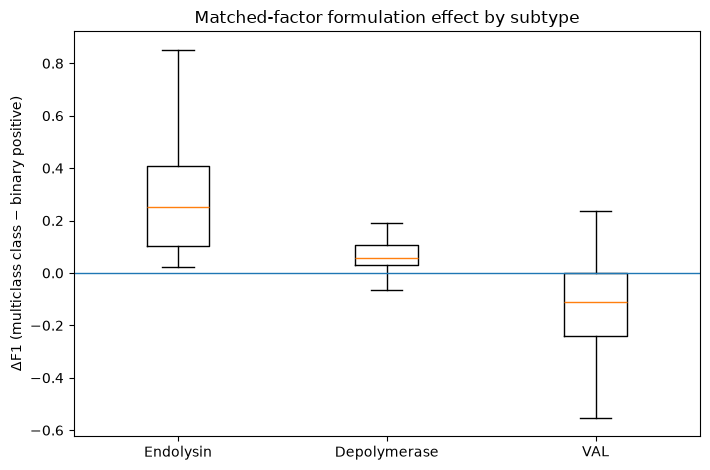

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 4.8))

data = [
    matched.loc[
        matched["subtype"].eq(s),
        "delta_f1_multi_minus_binary",
    ].dropna().to_numpy()
    for s in SUBTYPE_ORDER
]

ax.boxplot(
    data,
    tick_labels=[SUBTYPE_LABELS[s] for s in SUBTYPE_ORDER],
    showfliers=False,
)
ax.axhline(0, linewidth=1)
ax.set_ylabel("ΔF1 (multiclass class − binary positive)")
ax.set_title("Matched-factor formulation effect by subtype")
plt.tight_layout()
plt.show()

# 8. Recall and precision decomposition

In [12]:
decomposition_rows = []

for subtype, grp in matched.groupby("subtype"):
    row = {"subtype": subtype}

    if "delta_recall_multi_minus_binary" in grp.columns:
        row.update({
            "binary_recall_median": grp["binary_recall"].median(),
            "multiclass_recall_median": grp["multiclass_recall"].median(),
            "delta_recall_median": grp["delta_recall_multi_minus_binary"].median(),
            "fraction_recall_lower": (grp["delta_recall_multi_minus_binary"] < 0).mean(),
        })

    if "delta_precision_multi_minus_binary" in grp.columns:
        row.update({
            "binary_precision_median": grp["binary_precision"].median(),
            "multiclass_precision_median": grp["multiclass_precision"].median(),
            "delta_precision_median": grp["delta_precision_multi_minus_binary"].median(),
            "fraction_precision_lower": (grp["delta_precision_multi_minus_binary"] < 0).mean(),
        })

    decomposition_rows.append(row)

decomposition = (
    pd.DataFrame(decomposition_rows)
    .set_index("subtype")
    .reindex(SUBTYPE_ORDER)
)

display(decomposition)

,binary_recall_median,multiclass_recall_median,delta_recall_median,fraction_recall_lower,binary_precision_median,multiclass_precision_median,delta_precision_median,fraction_precision_lower
subtype,,,,,,,,
endolysin,0.716442,0.980822,0.265076,0.012500,0.836764,0.961846,0.119469,0.146875
depolymerase,0.835444,0.888474,0.067515,0.121875,0.892665,0.930306,0.035075,0.281250
val,0.380952,0.250000,-0.055556,0.603125,0.833333,0.500000,-0.230464,0.665625


This separates whether the formulation shift is driven mainly by:

- lost sensitivity to the target class;
- reduced positive predictive value;
- or both.

Because the competing populations differ, precision is particularly formulation-dependent and must not be interpreted without this context.

# 9. Permissive versus strict-corner formulation effects

In [13]:
corner_formulation = (
    matched[
        matched.apply(
            lambda r: (
                (r["R"], r["S"]) in [(90, 90), (30, 30)]
            ),
            axis=1,
        )
    ]
    .assign(
        corner=lambda x: np.where(
            x["R"].eq(90) & x["S"].eq(90),
            "R90_S90",
            "R30_S30",
        )
    )
    .groupby(["subtype", "corner"])
    .agg(
        binary_f1=("binary_f1", "median"),
        multiclass_f1=("multiclass_f1", "median"),
        delta_f1=("delta_f1_multi_minus_binary", "median"),
        fraction_multi_lower=("delta_f1_multi_minus_binary", lambda x: (x < 0).mean()),
    )
    .reset_index()
)

display(corner_formulation)

,subtype,corner,binary_f1,multiclass_f1,delta_f1,fraction_multi_lower
0,depolymerase,R30_S30,0.850537,0.915659,0.050746,0.00
1,depolymerase,R90_S90,0.867549,0.917083,0.066694,0.00
2,endolysin,R30_S30,0.631592,0.961094,0.332161,0.00
3,endolysin,R90_S90,0.803020,0.983143,0.179209,0.00
4,val,R30_S30,0.359098,0.230323,-0.161426,0.65
5,val,R90_S90,0.698837,0.489796,-0.164762,0.75


# 10. Does the formulation gap depend on R?

In [14]:
formulation_by_R = (
    matched.groupby(["subtype", "R"])
    .agg(
        binary_f1=("binary_f1", "median"),
        multiclass_f1=("multiclass_f1", "median"),
        delta_f1=("delta_f1_multi_minus_binary", "median"),
        delta_abs=("delta_f1_multi_minus_binary", lambda x: x.abs().median()),
        fraction_multi_lower=("delta_f1_multi_minus_binary", lambda x: (x < 0).mean()),
    )
    .reset_index()
)

display(formulation_by_R)

,subtype,R,binary_f1,multiclass_f1,delta_f1,delta_abs,fraction_multi_lower
0,depolymerase,30,0.853163,0.905544,0.047978,0.047978,0.0375
1,depolymerase,50,0.851274,0.896240,0.057401,0.057401,0.0750
2,depolymerase,70,0.831174,0.893002,0.046138,0.047235,0.0500
3,depolymerase,90,0.836725,0.909128,0.089357,0.089357,0.0125
4,endolysin,30,0.617068,0.959893,0.336749,0.336749,0.0000
5,endolysin,50,0.688729,0.963636,0.274195,0.274195,0.0000
6,endolysin,70,0.729468,0.972024,0.240064,0.240064,0.0000
7,endolysin,90,0.783400,0.980999,0.194588,0.194588,0.0000
8,val,30,0.375661,0.245000,-0.089899,0.125302,0.6375
9,val,50,0.250000,0.266667,-0.033873,0.114843,0.5500


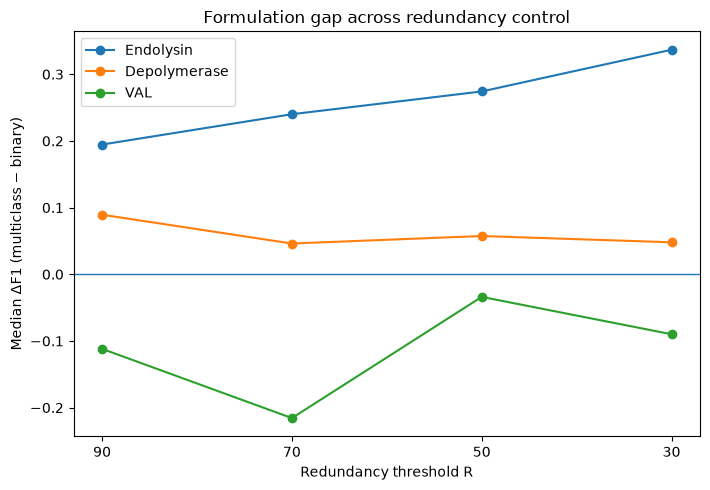

In [15]:
fig, ax = plt.subplots(figsize=(7.2, 5.0))

for subtype in SUBTYPE_ORDER:
    g = formulation_by_R[
        formulation_by_R["subtype"].eq(subtype)
    ].copy()
    g["R_order"] = g["R"].map(
        {90: 0, 70: 1, 50: 2, 30: 3}
    )
    g = g.sort_values("R_order")
    ax.plot(
        g["R"].astype(str),
        g["delta_f1"],
        marker="o",
        label=SUBTYPE_LABELS[subtype],
    )

ax.axhline(0, linewidth=1)
ax.set_xlabel("Redundancy threshold R")
ax.set_ylabel("Median ΔF1 (multiclass − binary)")
ax.set_title("Formulation gap across redundancy control")
ax.legend()
plt.tight_layout()
plt.show()

# 11. Does the formulation gap depend on S?

In [16]:
formulation_by_S = (
    matched.groupby(["subtype", "S"])
    .agg(
        binary_f1=("binary_f1", "median"),
        multiclass_f1=("multiclass_f1", "median"),
        delta_f1=("delta_f1_multi_minus_binary", "median"),
        delta_abs=("delta_f1_multi_minus_binary", lambda x: x.abs().median()),
        fraction_multi_lower=("delta_f1_multi_minus_binary", lambda x: (x < 0).mean()),
    )
    .reset_index()
)

display(formulation_by_S)

,subtype,S,binary_f1,multiclass_f1,delta_f1,delta_abs,fraction_multi_lower
0,depolymerase,30,0.835470,0.895591,0.050241,0.051455,0.1125
1,depolymerase,50,0.836344,0.906564,0.073293,0.073293,0.0375
2,depolymerase,70,0.843326,0.902296,0.051733,0.051733,0.0125
3,depolymerase,90,0.858325,0.899495,0.052938,0.052938,0.0125
4,endolysin,30,0.686421,0.964826,0.278232,0.278232,0.0000
5,endolysin,50,0.699888,0.968369,0.266647,0.266647,0.0000
6,endolysin,70,0.721222,0.970901,0.246332,0.246332,0.0000
7,endolysin,90,0.736248,0.971209,0.238913,0.238913,0.0000
8,val,30,0.285714,0.235294,-0.078276,0.129870,0.5750
9,val,50,0.375661,0.323929,-0.111217,0.157371,0.6875


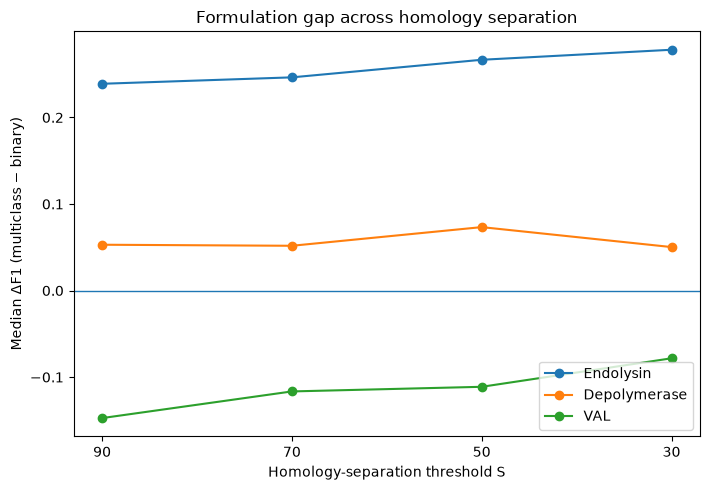

In [17]:
fig, ax = plt.subplots(figsize=(7.2, 5.0))

for subtype in SUBTYPE_ORDER:
    g = formulation_by_S[
        formulation_by_S["subtype"].eq(subtype)
    ].copy()
    g["S_order"] = g["S"].map(
        {90: 0, 70: 1, 50: 2, 30: 3}
    )
    g = g.sort_values("S_order")
    ax.plot(
        g["S"].astype(str),
        g["delta_f1"],
        marker="o",
        label=SUBTYPE_LABELS[subtype],
    )

ax.axhline(0, linewidth=1)
ax.set_xlabel("Homology-separation threshold S")
ax.set_ylabel("Median ΔF1 (multiclass − binary)")
ax.set_title("Formulation gap across homology separation")
ax.legend()
plt.tight_layout()
plt.show()

# 12. R sensitivity within each formulation

In [18]:
def extreme_R_effect(df, value_col, group_cols):
    rows = []

    for keys, grp in df.groupby(group_cols):
        if not isinstance(keys, tuple):
            keys = (keys,)

        lookup = dict(
            zip(
                grp["R"].astype(int),
                grp[value_col],
            )
        )

        if 90 in lookup and 30 in lookup:
            row = dict(zip(group_cols, keys))
            row["delta_R30_minus_R90"] = (
                lookup[30] - lookup[90]
            )
            rows.append(row)

    return pd.DataFrame(rows)

binary_R = extreme_R_effect(
    matched,
    "binary_f1",
    ["subtype", "S", "representation", "algorithm"],
)
binary_R["formulation"] = "binary"

multi_R = extreme_R_effect(
    matched,
    "multiclass_f1",
    ["subtype", "S", "representation", "algorithm"],
)
multi_R["formulation"] = "multiclass"

R_effects = pd.concat(
    [binary_R, multi_R],
    ignore_index=True,
)

R_summary = (
    R_effects.groupby(["subtype", "formulation"])
    ["delta_R30_minus_R90"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_negative=lambda x: (x < 0).mean(),
    )
    .reset_index()
)

display(R_summary)

,subtype,formulation,n,mean,median,median_abs,fraction_negative
0,depolymerase,binary,80,0.024931,0.020775,0.040199,0.3500
1,depolymerase,multiclass,80,-0.013821,-0.013573,0.018769,0.7375
2,endolysin,binary,80,-0.152818,-0.135535,0.135535,1.0000
3,endolysin,multiclass,80,-0.023180,-0.019489,0.019489,0.9875
4,val,binary,80,-0.066552,-0.053711,0.090909,0.6000
5,val,multiclass,80,-0.079422,-0.052401,0.081395,0.6875


# 13. S sensitivity within each formulation

In [19]:
def extreme_S_effect(df, value_col, group_cols):
    rows = []

    for keys, grp in df.groupby(group_cols):
        if not isinstance(keys, tuple):
            keys = (keys,)

        lookup = dict(
            zip(
                grp["S"].astype(int),
                grp[value_col],
            )
        )

        if 90 in lookup and 30 in lookup:
            row = dict(zip(group_cols, keys))
            row["delta_S30_minus_S90"] = (
                lookup[30] - lookup[90]
            )
            rows.append(row)

    return pd.DataFrame(rows)

binary_S = extreme_S_effect(
    matched,
    "binary_f1",
    ["subtype", "R", "representation", "algorithm"],
)
binary_S["formulation"] = "binary"

multi_S = extreme_S_effect(
    matched,
    "multiclass_f1",
    ["subtype", "R", "representation", "algorithm"],
)
multi_S["formulation"] = "multiclass"

S_effects = pd.concat(
    [binary_S, multi_S],
    ignore_index=True,
)

S_summary = (
    S_effects.groupby(["subtype", "formulation"])
    ["delta_S30_minus_S90"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_negative=lambda x: (x < 0).mean(),
    )
    .reset_index()
)

display(S_summary)

,subtype,formulation,n,mean,median,median_abs,fraction_negative
0,depolymerase,binary,80,-0.011879,-0.008907,0.021558,0.5875
1,depolymerase,multiclass,80,-0.021041,-0.018953,0.021041,0.7125
2,endolysin,binary,80,-0.026954,-0.016646,0.024477,0.7250
3,endolysin,multiclass,80,-0.004686,-0.004787,0.005772,0.8625
4,val,binary,80,-0.116961,-0.023790,0.070370,0.5500
5,val,multiclass,80,-0.071081,-0.071958,0.085055,0.6500


# 14. R×S non-additivity within each formulation

In [20]:
def extreme_interaction(df, value_col, formulation):
    rows = []

    for keys, grp in df.groupby(
        ["subtype", "representation", "algorithm"]
    ):
        subtype, rep, alg = keys

        lookup = {
            (int(r), int(s)): v
            for r, s, v in zip(
                grp["R"],
                grp["S"],
                grp[value_col],
            )
        }

        needed = [
            (90, 90),
            (90, 30),
            (30, 90),
            (30, 30),
        ]

        if all(k in lookup for k in needed):
            interaction = (
                (lookup[(30, 30)] - lookup[(30, 90)])
                - (lookup[(90, 30)] - lookup[(90, 90)])
            )

            rows.append({
                "subtype": subtype,
                "representation": rep,
                "algorithm": alg,
                "formulation": formulation,
                "interaction": interaction,
            })

    return pd.DataFrame(rows)

binary_interaction = extreme_interaction(
    matched,
    "binary_f1",
    "binary",
)

multi_interaction = extreme_interaction(
    matched,
    "multiclass_f1",
    "multiclass",
)

formulation_interactions = pd.concat(
    [binary_interaction, multi_interaction],
    ignore_index=True,
)

interaction_summary = (
    formulation_interactions.groupby(
        ["subtype", "formulation"]
    )["interaction"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_positive=lambda x: (x > 0).mean(),
    )
    .reset_index()
)

display(interaction_summary)

,subtype,formulation,n,mean,median,median_abs,fraction_positive
0,depolymerase,binary,20,0.051712,0.055905,0.055905,0.80
1,depolymerase,multiclass,20,0.017330,0.026704,0.034087,0.70
2,endolysin,binary,20,0.089032,0.072334,0.072334,0.95
3,endolysin,multiclass,20,0.005263,0.005260,0.005260,0.85
4,val,binary,20,0.337240,0.328710,0.328710,1.00
5,val,multiclass,20,0.172654,0.175197,0.175197,0.90


# 15. Representation dependence by formulation

In [21]:
def factor_spread(df, value_col, varying_col, group_cols):
    rows = []

    for keys, grp in df.groupby(group_cols):
        if not isinstance(keys, tuple):
            keys = (keys,)

        vals = grp.groupby(varying_col)[value_col].first().dropna()

        if len(vals) >= 2:
            row = dict(zip(group_cols, keys))
            row["range"] = vals.max() - vals.min()
            row["std"] = vals.std(ddof=0)
            rows.append(row)

    return pd.DataFrame(rows)

binary_rep_spread = factor_spread(
    matched,
    "binary_f1",
    "representation",
    ["subtype", "R", "S", "algorithm"],
)
binary_rep_spread["formulation"] = "binary"

multi_rep_spread = factor_spread(
    matched,
    "multiclass_f1",
    "representation",
    ["subtype", "R", "S", "algorithm"],
)
multi_rep_spread["formulation"] = "multiclass"

rep_spread = pd.concat(
    [binary_rep_spread, multi_rep_spread],
    ignore_index=True,
)

display(
    rep_spread.groupby(
        ["subtype", "formulation"]
    )
    .agg(
        median_representation_range=("range", "median"),
        mean_representation_range=("range", "mean"),
    )
    .reset_index()
)

,subtype,formulation,median_representation_range,mean_representation_range
0,depolymerase,binary,0.339906,0.430807
1,depolymerase,multiclass,0.222618,0.227240
2,endolysin,binary,0.467039,0.513726
3,endolysin,multiclass,0.036141,0.044528
4,val,binary,0.711982,0.679396
5,val,multiclass,0.434653,0.436599


# 16. ESM2 capacity gain by formulation

In [22]:
def paired_rep_effect(df, value_col, hi, lo, formulation):
    rows = []

    for keys, grp in df.groupby(
        ["subtype", "R", "S", "algorithm"]
    ):
        subtype, r, s, alg = keys
        lookup = dict(
            zip(
                grp["representation"],
                grp[value_col],
            )
        )

        if hi in lookup and lo in lookup:
            rows.append({
                "subtype": subtype,
                "R": int(r),
                "S": int(s),
                "algorithm": alg,
                "formulation": formulation,
                "delta": lookup[hi] - lookup[lo],
            })

    return pd.DataFrame(rows)

binary_capacity = paired_rep_effect(
    matched,
    "binary_f1",
    T30,
    T6,
    "binary",
)

multi_capacity = paired_rep_effect(
    matched,
    "multiclass_f1",
    T30,
    T6,
    "multiclass",
)

capacity_effects = pd.concat(
    [binary_capacity, multi_capacity],
    ignore_index=True,
)

capacity_summary = (
    capacity_effects.groupby(
        ["subtype", "formulation"]
    )["delta"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_gt_005=lambda x: (x > 0.05).mean(),
    )
    .reset_index()
)

display(capacity_summary)

,subtype,formulation,n,mean,median,fraction_positive,fraction_gt_005
0,depolymerase,binary,80,0.029361,0.022312,0.8375,0.2250
1,depolymerase,multiclass,80,0.023716,0.019195,0.9375,0.0875
2,endolysin,binary,80,0.122784,0.119285,1.0000,0.9875
3,endolysin,multiclass,80,0.004937,0.004197,0.9000,0.0000
4,val,binary,80,0.166428,0.130062,0.9375,0.9000
5,val,multiclass,80,0.097453,0.104635,0.7875,0.6500


# 17. T30 versus one-hot by formulation

In [23]:
binary_t30_onehot = paired_rep_effect(
    matched,
    "binary_f1",
    T30,
    ONEHOT,
    "binary",
)

multi_t30_onehot = paired_rep_effect(
    matched,
    "multiclass_f1",
    T30,
    ONEHOT,
    "multiclass",
)

t30_onehot_effects = pd.concat(
    [binary_t30_onehot, multi_t30_onehot],
    ignore_index=True,
)

display(
    t30_onehot_effects.groupby(
        ["subtype", "formulation"]
    )["delta"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        fraction_positive=lambda x: (x > 0).mean(),
    )
    .reset_index()
)

,subtype,formulation,n,mean,median,fraction_positive
0,depolymerase,binary,80,0.375508,0.278910,1.0
1,depolymerase,multiclass,80,0.226769,0.222618,1.0
2,endolysin,binary,80,0.511706,0.467039,1.0
3,endolysin,multiclass,80,0.032473,0.030003,1.0
4,val,binary,80,0.668230,0.700733,1.0
5,val,multiclass,80,0.423706,0.427705,1.0


# 18. Does representation quality change the formulation gap?

In [24]:
formulation_by_rep = (
    matched.groupby(
        ["subtype", "representation"]
    )
    .agg(
        binary_f1=("binary_f1", "median"),
        multiclass_f1=("multiclass_f1", "median"),
        delta_f1=("delta_f1_multi_minus_binary", "median"),
        delta_abs=("delta_f1_multi_minus_binary", lambda x: x.abs().median()),
        fraction_multi_lower=("delta_f1_multi_minus_binary", lambda x: (x < 0).mean()),
    )
    .reset_index()
)

display(formulation_by_rep)

,subtype,representation,binary_f1,multiclass_f1,delta_f1,delta_abs,fraction_multi_lower
0,depolymerase,esm2_t30_150m,0.907403,0.961725,0.047235,0.047235,0.0125
1,depolymerase,esm2_t6_8m,0.887200,0.935578,0.050411,0.050411,0.0375
2,depolymerase,onehot_1024,0.629515,0.734253,0.115304,0.115304,0.0500
3,depolymerase,roxy_48,0.817241,0.864010,0.052636,0.052636,0.0750
4,endolysin,esm2_t30_150m,0.922180,0.978522,0.059667,0.059667,0.0000
5,endolysin,esm2_t6_8m,0.782547,0.973333,0.190193,0.190193,0.0000
6,endolysin,onehot_1024,0.429306,0.948216,0.511002,0.511002,0.0000
7,endolysin,roxy_48,0.617017,0.961324,0.333962,0.333962,0.0000
8,val,esm2_t30_150m,0.778401,0.494444,-0.230616,0.230616,1.0000
9,val,esm2_t6_8m,0.616783,0.421182,-0.183073,0.186811,0.8750


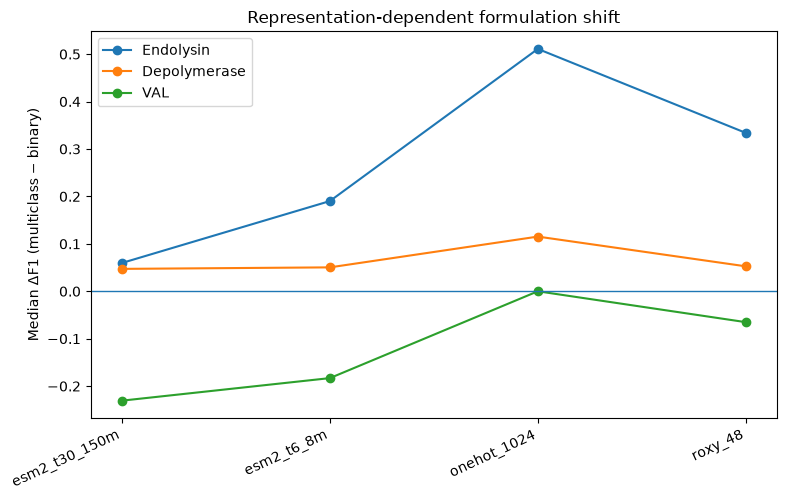

In [25]:
fig, ax = plt.subplots(figsize=(8.0, 5.1))

x_labels = REPS
x = np.arange(len(x_labels))

for subtype in SUBTYPE_ORDER:
    g = (
        formulation_by_rep[
            formulation_by_rep["subtype"].eq(subtype)
        ]
        .set_index("representation")
        .reindex(x_labels)
    )
    ax.plot(
        x,
        g["delta_f1"],
        marker="o",
        label=SUBTYPE_LABELS[subtype],
    )

ax.axhline(0, linewidth=1)
ax.set_xticks(x, x_labels, rotation=25, ha="right")
ax.set_ylabel("Median ΔF1 (multiclass − binary)")
ax.set_title("Representation-dependent formulation shift")
ax.legend()
plt.tight_layout()
plt.show()

This is a central RQ11 analysis.

If the formulation penalty contracts with stronger PLMs, a plausible interpretation is that better feature spaces make discrimination among lytic subclasses easier.

If the gap persists even with T30, the limitation is more likely tied to the biological/task formulation itself than to representation quality alone.

# 19. Algorithm dependence by formulation

In [26]:
binary_alg_spread = factor_spread(
    matched,
    "binary_f1",
    "algorithm",
    ["subtype", "R", "S", "representation"],
)
binary_alg_spread["formulation"] = "binary"

multi_alg_spread = factor_spread(
    matched,
    "multiclass_f1",
    "algorithm",
    ["subtype", "R", "S", "representation"],
)
multi_alg_spread["formulation"] = "multiclass"

alg_spread = pd.concat(
    [binary_alg_spread, multi_alg_spread],
    ignore_index=True,
)

algorithm_dependence = (
    alg_spread.groupby(
        ["subtype", "formulation"]
    )
    .agg(
        median_algorithm_range=("range", "median"),
        mean_algorithm_range=("range", "mean"),
    )
    .reset_index()
)

display(algorithm_dependence)

,subtype,formulation,median_algorithm_range,mean_algorithm_range
0,depolymerase,binary,0.211938,0.313776
1,depolymerase,multiclass,0.051839,0.065400
2,endolysin,binary,0.150810,0.215915
3,endolysin,multiclass,0.013171,0.028372
4,val,binary,0.360078,0.355258
5,val,multiclass,0.264900,0.254792


# 20. Does classifier identity change the formulation gap?

In [27]:
formulation_by_algorithm = (
    matched.groupby(
        ["subtype", "algorithm"]
    )
    .agg(
        binary_f1=("binary_f1", "median"),
        multiclass_f1=("multiclass_f1", "median"),
        delta_f1=("delta_f1_multi_minus_binary", "median"),
        fraction_multi_lower=("delta_f1_multi_minus_binary", lambda x: (x < 0).mean()),
    )
    .reset_index()
)

display(formulation_by_algorithm)

,subtype,algorithm,binary_f1,multiclass_f1,delta_f1,fraction_multi_lower
0,depolymerase,KNN,0.860725,0.898662,0.047796,0.015625
1,depolymerase,LR,0.767880,0.884783,0.094445,0.062500
2,depolymerase,MLP,0.858388,0.910191,0.050486,0.062500
3,depolymerase,RF,0.850719,0.892982,0.061679,0.046875
4,depolymerase,XGB,0.856642,0.912058,0.051390,0.031250
5,endolysin,KNN,0.740176,0.969052,0.230523,0.000000
6,endolysin,LR,0.630719,0.962986,0.320341,0.000000
7,endolysin,MLP,0.768016,0.972340,0.204921,0.000000
8,endolysin,RF,0.651960,0.966978,0.321586,0.000000
9,endolysin,XGB,0.764701,0.970781,0.210194,0.000000


# 21. Do model rankings transfer between formulations?

In [28]:
rank_transfer_rows = []

for subtype in SUBTYPE_ORDER:
    g = matched[
        matched["subtype"].eq(subtype)
    ][
        ["binary_f1", "multiclass_f1"]
    ].dropna()

    rank_transfer_rows.append({
        "subtype": subtype,
        "n_matched_models": len(g),
        "spearman_binary_vs_multiclass_f1": (
            g["binary_f1"].corr(
                g["multiclass_f1"],
                method="spearman",
            )
        ),
    })

rank_transfer = pd.DataFrame(rank_transfer_rows)
display(rank_transfer)

,subtype,n_matched_models,spearman_binary_vs_multiclass_f1
0,endolysin,320,0.885061
1,depolymerase,320,0.865821
2,val,320,0.861328


The pooled rank correlation asks whether model configurations that perform well in the binary formulation also tend to perform well for the same biological class in multiclass discrimination.

Because R/S populations differ across cells, the more conservative check is performed next **within each R×S cell** across the 20 representation×algorithm configurations.

In [29]:
within_cell_rank_rows = []

for keys, grp in matched.groupby(
    ["subtype", "R", "S"]
):
    subtype, r, s = keys

    g = grp[
        ["binary_f1", "multiclass_f1"]
    ].dropna()

    rho = (
        g["binary_f1"].corr(
            g["multiclass_f1"],
            method="spearman",
        )
        if len(g) >= 5
        else np.nan
    )

    within_cell_rank_rows.append({
        "subtype": subtype,
        "R": int(r),
        "S": int(s),
        "n_models": len(g),
        "spearman_rank_transfer": rho,
    })

within_cell_rank = pd.DataFrame(
    within_cell_rank_rows
)

display(
    within_cell_rank.groupby("subtype")[
        "spearman_rank_transfer"
    ]
    .agg(
        mean="mean",
        median="median",
        min="min",
        max="max",
        fraction_positive=lambda x: (x > 0).mean(),
    )
    .reindex(SUBTYPE_ORDER)
)

,mean,median,min,max,fraction_positive
subtype,,,,,
endolysin,0.932400,0.935338,0.893233,0.962406,1.0
depolymerase,0.913515,0.916541,0.851016,0.971429,1.0
val,0.884866,0.887379,0.801741,0.964945,1.0


# 22. Multiclass global performance versus class-specific resolution

In [30]:
multi_global = multi_master[
    [
        "R",
        "S",
        "representation",
        "algorithm",
        "mcc",
        *(
            ["macro_f1"]
            if "macro_f1" in multi_master.columns
            else []
        ),
    ]
].copy()

multi_class_wide = (
    multi_class.pivot_table(
        index=[
            "R",
            "S",
            "representation",
            "algorithm",
        ],
        columns="subtype",
        values="multiclass_f1",
        aggfunc="first",
    )
    .reset_index()
)

global_vs_class = multi_global.merge(
    multi_class_wide,
    on=[
        "R",
        "S",
        "representation",
        "algorithm",
    ],
    how="inner",
    validate="one_to_one",
)

display(
    global_vs_class[
        [
            "mcc",
            *(
                ["macro_f1"]
                if "macro_f1" in global_vs_class.columns
                else []
            ),
            *SUBTYPE_ORDER,
        ]
    ].corr(method="spearman")
)

,mcc,macro_f1,endolysin,depolymerase,val
mcc,1.000000,0.912472,0.864086,0.965535,0.819610
macro_f1,0.912472,1.000000,0.800839,0.906304,0.976584
endolysin,0.864086,0.800839,1.000000,0.804909,0.718447
depolymerase,0.965535,0.906304,0.804909,1.000000,0.811456
val,0.819610,0.976584,0.718447,0.811456,1.000000


In [31]:
global_vs_class["worst_class_f1"] = (
    global_vs_class[SUBTYPE_ORDER].min(axis=1)
)

global_vs_class["best_class_f1"] = (
    global_vs_class[SUBTYPE_ORDER].max(axis=1)
)

global_vs_class["class_f1_range"] = (
    global_vs_class["best_class_f1"]
    - global_vs_class["worst_class_f1"]
)

display(
    global_vs_class[
        [
            "mcc",
            "worst_class_f1",
            "best_class_f1",
            "class_f1_range",
        ]
    ].describe()
)

,mcc,worst_class_f1,best_class_f1,class_f1_range
count,320.000000,320.000000,320.000000,320.000000
mean,0.776218,0.293505,0.962415,0.668910
std,0.105645,0.205473,0.023727,0.192814
min,0.474300,0.000000,0.852492,0.221835
25%,0.692556,0.111111,0.956974,0.523144
50%,0.811130,0.298936,0.968665,0.650029
75%,0.860198,0.451786,0.977816,0.843425
max,0.932059,0.769231,0.992308,0.981413


This tests whether a strong aggregate multiclass score can coexist with poor resolution of the weakest class. RQ10 already showed that VAL can be poorly resolved despite respectable global multiclass performance; RQ11 generalizes that check across all multiclass configurations.

# 23. Multiclass confusion structure from frozen predictions

In [32]:
def multiclass_experiment_dir(r, s, representation, algorithm):
    return (
        TRAINING_ROOT
        / TASK_PATHS[MULTI_TASK]
        / f"R{r}_S{s}"
        / representation
        / algorithm
    )

prediction_frames = []
missing_predictions = []

for r in R_LEVELS:
    for s in S_LEVELS:
        for rep in REPS:
            for alg in ALGORITHMS:
                p = (
                    multiclass_experiment_dir(
                        r, s, rep, alg
                    )
                    / "outer_test_predictions.parquet"
                )

                if not p.is_file():
                    missing_predictions.append(str(p))
                    continue

                pred = pd.read_parquet(p)

                required = {"y_true", "y_pred"}
                missing = required - set(pred.columns)
                if missing:
                    raise KeyError(
                        f"{p}: missing {sorted(missing)}"
                    )

                pred = pred[
                    ["y_true", "y_pred"]
                ].copy()

                pred["R"] = r
                pred["S"] = s
                pred["representation"] = rep
                pred["algorithm"] = alg

                prediction_frames.append(pred)

if missing_predictions:
    raise FileNotFoundError(
        f"Missing {len(missing_predictions)} multiclass prediction files. "
        f"First: {missing_predictions[0]}"
    )

multi_predictions = pd.concat(
    prediction_frames,
    ignore_index=True,
)

print("Prediction rows:", len(multi_predictions))
print(
    "Model families:",
    multi_predictions[
        ["R", "S", "representation", "algorithm"]
    ].drop_duplicates().shape[0],
)

Prediction rows: 280440
Model families: 320


# 24. Map multiclass prediction labels to biological classes

In [33]:
def map_prediction_label(value):
    text_mapped = canonical_subtype_from_text(value)
    if text_mapped is not None:
        return text_mapped

    key = str(value)

    if key in label_mapping:
        return label_mapping[key]

    try:
        key2 = str(int(float(value)))
        return label_mapping.get(key2)
    except Exception:
        return None

multi_predictions["true_subtype"] = (
    multi_predictions["y_true"]
    .map(map_prediction_label)
)

multi_predictions["pred_subtype"] = (
    multi_predictions["y_pred"]
    .map(map_prediction_label)
)

unmapped_true = (
    multi_predictions.loc[
        multi_predictions["true_subtype"].isna(),
        "y_true",
    ]
    .drop_duplicates()
    .tolist()
)

unmapped_pred = (
    multi_predictions.loc[
        multi_predictions["pred_subtype"].isna(),
        "y_pred",
    ]
    .drop_duplicates()
    .tolist()
)

if unmapped_true or unmapped_pred:
    raise RuntimeError(
        f"Unmapped prediction labels. "
        f"true={unmapped_true}, pred={unmapped_pred}"
    )

display(
    multi_predictions[
        ["y_true", "true_subtype"]
    ].drop_duplicates()
)

display(
    multi_predictions[
        ["y_pred", "pred_subtype"]
    ].drop_duplicates()
)

,y_true,true_subtype
0,1,depolymerase
13,0,endolysin
30,2,val


,y_pred,pred_subtype
0,1,depolymerase
15,0,endolysin
30,2,val


# 25. Per-model normalized confusion profiles

In [34]:
confusion_rows = []

for keys, grp in multi_predictions.groupby(
    ["R", "S", "representation", "algorithm"]
):
    r, s, rep, alg = keys

    for true_subtype in SUBTYPE_ORDER:
        true_grp = grp[
            grp["true_subtype"].eq(true_subtype)
        ]

        n_true = len(true_grp)

        if n_true == 0:
            continue

        for pred_subtype in SUBTYPE_ORDER:
            count = int(
                true_grp[
                    "pred_subtype"
                ].eq(pred_subtype).sum()
            )

            confusion_rows.append({
                "R": int(r),
                "S": int(s),
                "representation": rep,
                "algorithm": alg,
                "true_subtype": true_subtype,
                "pred_subtype": pred_subtype,
                "n_true": n_true,
                "count": count,
                "fraction": count / n_true,
            })

confusion_long = pd.DataFrame(
    confusion_rows
)

confusion_summary = (
    confusion_long.groupby(
        ["true_subtype", "pred_subtype"]
    )["fraction"]
    .agg(
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

display(confusion_summary)

,true_subtype,pred_subtype,mean,median,q25,q75
0,depolymerase,depolymerase,0.970117,0.980822,0.967538,0.989499
1,depolymerase,endolysin,0.015912,0.008772,0.003210,0.023753
2,depolymerase,val,0.013972,0.005405,0.001684,0.012735
3,endolysin,depolymerase,0.139272,0.101582,0.056154,0.218412
4,endolysin,endolysin,0.854727,0.888474,0.781588,0.933471
5,endolysin,val,0.006001,0.000000,0.000000,0.000000
6,val,depolymerase,0.616644,0.639444,0.500000,0.777778
7,val,endolysin,0.101125,0.062500,0.000000,0.166667
8,val,val,0.282230,0.250000,0.066667,0.455492


pred_subtype,endolysin,depolymerase,val
true_subtype,,,
endolysin,0.888474,0.101582,0.000000
depolymerase,0.008772,0.980822,0.005405
val,0.062500,0.639444,0.250000


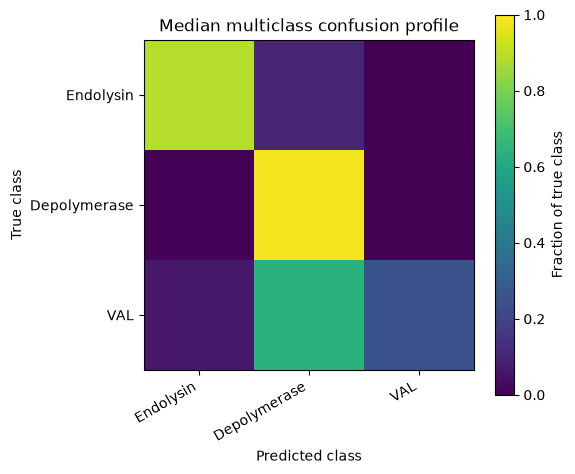

In [35]:
confusion_matrix_median = (
    confusion_summary.pivot(
        index="true_subtype",
        columns="pred_subtype",
        values="median",
    )
    .reindex(
        index=SUBTYPE_ORDER,
        columns=SUBTYPE_ORDER,
    )
)

display(confusion_matrix_median)

fig, ax = plt.subplots(figsize=(5.8, 5.0))
im = ax.imshow(
    confusion_matrix_median.to_numpy(),
    vmin=0,
    vmax=1,
    aspect="equal",
)

ax.set_xticks(
    range(len(SUBTYPE_ORDER)),
    [SUBTYPE_LABELS[s] for s in SUBTYPE_ORDER],
    rotation=30,
    ha="right",
)

ax.set_yticks(
    range(len(SUBTYPE_ORDER)),
    [SUBTYPE_LABELS[s] for s in SUBTYPE_ORDER],
)

ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Median multiclass confusion profile")
plt.colorbar(im, ax=ax, label="Fraction of true class")
plt.tight_layout()
plt.show()

# 26. Dominant off-diagonal confusions

In [36]:
off_diag = confusion_summary[
    confusion_summary["true_subtype"]
    != confusion_summary["pred_subtype"]
].copy()

display(
    off_diag.sort_values(
        "median",
        ascending=False,
    )
)

,true_subtype,pred_subtype,mean,median,q25,q75
6,val,depolymerase,0.616644,0.639444,0.500000,0.777778
3,endolysin,depolymerase,0.139272,0.101582,0.056154,0.218412
7,val,endolysin,0.101125,0.062500,0.000000,0.166667
1,depolymerase,endolysin,0.015912,0.008772,0.003210,0.023753
2,depolymerase,val,0.013972,0.005405,0.001684,0.012735
5,endolysin,val,0.006001,0.000000,0.000000,0.000000


# 27. Does representation alter multiclass confusion?

In [37]:
confusion_by_rep = (
    confusion_long.groupby(
        [
            "representation",
            "true_subtype",
            "pred_subtype",
        ]
    )["fraction"]
    .median()
    .reset_index()
)

for subtype in SUBTYPE_ORDER:
    print("\nTrue class:", SUBTYPE_LABELS[subtype])
    display(
        confusion_by_rep[
            confusion_by_rep["true_subtype"].eq(subtype)
        ].pivot(
            index="representation",
            columns="pred_subtype",
            values="fraction",
        ).reindex(REPS)
    )


True class: Endolysin


pred_subtype,depolymerase,endolysin,val
representation,,,
esm2_t30_150m,0.048810,0.945011,0.0
esm2_t6_8m,0.076179,0.917633,0.0
onehot_1024,0.279286,0.720714,0.0
roxy_48,0.121499,0.865873,0.0



True class: Depolymerase


pred_subtype,depolymerase,endolysin,val
representation,,,
esm2_t30_150m,0.986826,0.002573,0.010502
esm2_t6_8m,0.986486,0.003601,0.009804
onehot_1024,0.971930,0.028070,0.000000
roxy_48,0.972997,0.017744,0.005959



True class: VAL


pred_subtype,depolymerase,endolysin,val
representation,,,
esm2_t30_150m,0.500000,0.000000,0.466667
esm2_t6_8m,0.587121,0.028595,0.362374
onehot_1024,0.772727,0.190909,0.000000
roxy_48,0.637626,0.136364,0.215278


This identifies whether stronger representations primarily improve multiclass performance by:

- increasing correct class recognition;
- reducing one specific biologically adjacent confusion;
- or reducing all off-diagonal errors more uniformly.

# 28. Strict-corner confusion profile

In [38]:
strict_confusion = (
    confusion_long[
        confusion_long["R"].eq(30)
        & confusion_long["S"].eq(30)
    ]
    .groupby(
        ["true_subtype", "pred_subtype"]
    )["fraction"]
    .median()
    .unstack()
    .reindex(
        index=SUBTYPE_ORDER,
        columns=SUBTYPE_ORDER,
    )
)

display(strict_confusion)

pred_subtype,endolysin,depolymerase,val
true_subtype,,,
endolysin,0.927778,0.072222,0.000000
depolymerase,0.017663,0.968750,0.008152
val,0.107143,0.607143,0.142857


# 29. Binary versus multiclass formulation under T30

In [39]:
t30_summary = (
    matched[
        matched["representation"].eq(T30)
    ]
    .groupby("subtype")
    .agg(
        binary_f1=("binary_f1", "median"),
        multiclass_f1=("multiclass_f1", "median"),
        delta_f1=("delta_f1_multi_minus_binary", "median"),
        fraction_multi_lower=("delta_f1_multi_minus_binary", lambda x: (x < 0).mean()),
    )
    .reindex(SUBTYPE_ORDER)
)

display(t30_summary)

strict_t30 = (
    matched[
        matched["representation"].eq(T30)
        & matched["R"].eq(30)
        & matched["S"].eq(30)
    ]
    .groupby("subtype")
    .agg(
        binary_f1=("binary_f1", "median"),
        multiclass_f1=("multiclass_f1", "median"),
        delta_f1=("delta_f1_multi_minus_binary", "median"),
    )
    .reindex(SUBTYPE_ORDER)
)

print("T30 at R30/S30")
display(strict_t30)

,binary_f1,multiclass_f1,delta_f1,fraction_multi_lower
subtype,,,,
endolysin,0.922180,0.978522,0.059667,0.0000
depolymerase,0.907403,0.961725,0.047235,0.0125
val,0.778401,0.494444,-0.230616,1.0000


T30 at R30/S30


,binary_f1,multiclass_f1,delta_f1
subtype,,,
endolysin,0.889527,0.974290,0.086280
depolymerase,0.925714,0.971429,0.045714
val,0.774194,0.434783,-0.279503


This is particularly important for interpretation.

If a large formulation gap remains even with T30 under strict R/S, the difference cannot be dismissed as a weak-representation artifact.

# 30. Formulation sensitivity fingerprint

In [40]:
def summarize_effect_table(df, value_col):
    return (
        df.groupby(
            ["subtype", "formulation"]
        )[value_col]
        .agg(
            median="median",
            median_abs=lambda x: x.abs().median(),
        )
        .reset_index()
    )

r_fp = summarize_effect_table(
    R_effects,
    "delta_R30_minus_R90",
).rename(
    columns={
        "median": "R_signed",
        "median_abs": "R_abs",
    }
)

s_fp = summarize_effect_table(
    S_effects,
    "delta_S30_minus_S90",
).rename(
    columns={
        "median": "S_signed",
        "median_abs": "S_abs",
    }
)

i_fp = summarize_effect_table(
    formulation_interactions,
    "interaction",
).rename(
    columns={
        "median": "RxS_signed",
        "median_abs": "RxS_abs",
    }
)

rep_fp = (
    rep_spread.groupby(
        ["subtype", "formulation"]
    )["range"]
    .median()
    .rename("representation_range")
    .reset_index()
)

alg_fp = (
    alg_spread.groupby(
        ["subtype", "formulation"]
    )["range"]
    .median()
    .rename("algorithm_range")
    .reset_index()
)

cap_fp = (
    capacity_effects.groupby(
        ["subtype", "formulation"]
    )["delta"]
    .median()
    .rename("T30_minus_T6")
    .reset_index()
)

fingerprint = (
    r_fp
    .merge(s_fp, on=["subtype", "formulation"])
    .merge(i_fp, on=["subtype", "formulation"])
    .merge(rep_fp, on=["subtype", "formulation"])
    .merge(alg_fp, on=["subtype", "formulation"])
    .merge(cap_fp, on=["subtype", "formulation"])
)

display(fingerprint)

,subtype,formulation,R_signed,R_abs,S_signed,S_abs,RxS_signed,RxS_abs,representation_range,algorithm_range,T30_minus_T6
0,depolymerase,binary,0.020775,0.040199,-0.008907,0.021558,0.055905,0.055905,0.339906,0.211938,0.022312
1,depolymerase,multiclass,-0.013573,0.018769,-0.018953,0.021041,0.026704,0.034087,0.222618,0.051839,0.019195
2,endolysin,binary,-0.135535,0.135535,-0.016646,0.024477,0.072334,0.072334,0.467039,0.150810,0.119285
3,endolysin,multiclass,-0.019489,0.019489,-0.004787,0.005772,0.005260,0.005260,0.036141,0.013171,0.004197
4,val,binary,-0.053711,0.090909,-0.023790,0.070370,0.328710,0.328710,0.711982,0.360078,0.130062
5,val,multiclass,-0.052401,0.081395,-0.071958,0.085055,0.175197,0.175197,0.434653,0.264900,0.104635


# 31. Difference in generalization fingerprint caused by formulation

In [41]:
fp_delta_rows = []

for subtype in SUBTYPE_ORDER:
    b = fingerprint[
        fingerprint["subtype"].eq(subtype)
        & fingerprint["formulation"].eq("binary")
    ].iloc[0]

    m = fingerprint[
        fingerprint["subtype"].eq(subtype)
        & fingerprint["formulation"].eq("multiclass")
    ].iloc[0]

    row = {"subtype": subtype}

    for c in [
        "R_signed",
        "R_abs",
        "S_signed",
        "S_abs",
        "RxS_signed",
        "RxS_abs",
        "representation_range",
        "algorithm_range",
        "T30_minus_T6",
    ]:
        row[f"multiclass_minus_binary_{c}"] = (
            m[c] - b[c]
        )

    fp_delta_rows.append(row)

fingerprint_shift = pd.DataFrame(
    fp_delta_rows
).set_index("subtype")

display(fingerprint_shift)

,multiclass_minus_binary_R_signed,multiclass_minus_binary_R_abs,multiclass_minus_binary_S_signed,multiclass_minus_binary_S_abs,multiclass_minus_binary_RxS_signed,multiclass_minus_binary_RxS_abs,multiclass_minus_binary_representation_range,multiclass_minus_binary_algorithm_range,multiclass_minus_binary_T30_minus_T6
subtype,,,,,,,,,
endolysin,0.116047,-0.116047,0.011859,-0.018705,-0.067074,-0.067074,-0.430897,-0.137639,-0.115088
depolymerase,-0.034348,-0.021430,-0.010046,-0.000517,-0.029201,-0.021818,-0.117288,-0.160099,-0.003117
val,0.001310,-0.009514,-0.048167,0.014684,-0.153513,-0.153513,-0.277328,-0.095177,-0.025427


RQ11 is not only asking whether class F1 changes.

The fingerprint shift asks whether changing the biological formulation changes **what the task is sensitive to**:

- redundancy;
- remote homology;
- R×S interaction;
- representation quality;
- classifier choice;
- PLM capacity.

A strong fingerprint shift means binary and multiclass are genuinely different generalization problems even for the same named biological subtype.

# 32. Compact manuscript-ready regime table

In [42]:
regime_table = (
    formulation_summary[
        [
            "binary_f1_median",
            "multiclass_f1_median",
            "delta_f1_median",
            "fraction_multi_lower",
        ]
    ]
    .join(
        decomposition[
            [
                c for c in [
                    "delta_recall_median",
                    "delta_precision_median",
                ]
                if c in decomposition.columns
            ]
        ],
        how="left",
    )
)

# Add T30 and strict-corner formulation gaps.
regime_table["T30_delta_f1"] = (
    t30_summary["delta_f1"]
)

strict_gap = (
    corner_formulation[
        corner_formulation["corner"].eq("R30_S30")
    ]
    .set_index("subtype")["delta_f1"]
)

regime_table["strict_R30S30_delta_f1"] = (
    strict_gap
)

# Add rank transfer.
regime_table = regime_table.join(
    rank_transfer.set_index("subtype")[
        ["spearman_binary_vs_multiclass_f1"]
    ],
    how="left",
)

display(regime_table)

,binary_f1_median,multiclass_f1_median,delta_f1_median,fraction_multi_lower,delta_recall_median,delta_precision_median,T30_delta_f1,strict_R30S30_delta_f1,spearman_binary_vs_multiclass_f1
subtype,,,,,,,,,
endolysin,0.718985,0.968665,0.252031,0.000000,0.265076,0.119469,0.059667,0.332161,0.885061
depolymerase,0.842912,0.899851,0.058476,0.043750,0.067515,0.035075,0.047235,0.050746,0.865821
val,0.400000,0.298936,-0.111822,0.653125,-0.055556,-0.230464,-0.230616,-0.161426,0.861328


# 33. RQ11 synthesis questions

After execution, RQ11 should answer:

1. Is subtype-vs-background recognition systematically easier or harder than clean subtype discrimination?
2. Does the formulation effect differ among endolysin, depolymerase, and VAL?
3. Is the effect driven primarily by recall, precision, or both?
4. Does the binary→multiclass formulation shift grow under stricter R or S?
5. Does multiclass discrimination show different R/S sensitivities from binary recognition?
6. Does multiclass exhibit stronger or weaker R×S non-additivity?
7. Does representation quality reduce the formulation gap?
8. Is the T30 capacity benefit similar across formulations?
9. Does classifier choice matter more in binary or multiclass settings?
10. Do the same representation×algorithm combinations rank highly in both formulations?
11. Which lytic classes are most commonly confused with one another?
12. Do stronger PLMs reduce specific biological confusions?
13. Can a strong global multiclass MCC coexist with poor class-specific F1?
14. Does the Low-N VAL limitation become more severe when exclusivity must also be resolved?
15. Does changing task formulation change the full generalization fingerprint, not merely absolute performance?

The desired scientific conclusion is not:

> “binary is better than multiclass.”

The useful conclusion is:

> **Binary subtype recognition and multiclass functional discrimination expose different aspects of the same biological annotation problem and can occupy different generalization regimes.**

## Manuscript-level conceptual target

If supported by the executed analysis:

> **Functional task formulation changes what constitutes successful generalization. Independent binary classifiers test whether a subtype can be separated from non-lytic background, whereas multiclass models additionally require discrimination among related lytic functions. Consequently, class-specific performance, sensitivity to redundancy and homology separation, dependence on representation quality, and the structure of prediction errors can differ even when the named biological subtype is unchanged.**

The broader methodological point is:

> **A protein-function benchmark is defined not only by its labels, but by the decision problem those labels are asked to support.**

# 34. Export RQ11 cache tables

In [43]:
MATCHED_PATH = CACHE_DIR / "rq11_binary_multiclass_matched_formulation.tsv"
SUMMARY_PATH = CACHE_DIR / "rq11_formulation_summary.tsv"
DECOMP_PATH = CACHE_DIR / "rq11_recall_precision_decomposition.tsv"
R_PATH = CACHE_DIR / "rq11_formulation_R_effects.tsv"
S_PATH = CACHE_DIR / "rq11_formulation_S_effects.tsv"
INTERACTION_PATH = CACHE_DIR / "rq11_formulation_RxS_interactions.tsv"
REP_PATH = CACHE_DIR / "rq11_formulation_representation_dependence.tsv"
CAPACITY_PATH = CACHE_DIR / "rq11_formulation_T30_T6.tsv"
ALG_PATH = CACHE_DIR / "rq11_formulation_algorithm_dependence.tsv"
RANK_PATH = CACHE_DIR / "rq11_formulation_rank_transfer.tsv"
CONFUSION_PATH = CACHE_DIR / "rq11_multiclass_confusion_profiles.tsv"
FINGERPRINT_PATH = CACHE_DIR / "rq11_formulation_fingerprint.tsv"
FINGERPRINT_SHIFT_PATH = CACHE_DIR / "rq11_formulation_fingerprint_shift.tsv"
REGIME_PATH = CACHE_DIR / "rq11_regime_table.tsv"
SUPPORT_PATH = CACHE_DIR / "rq11_binary_multiclass_support.tsv"

matched.to_csv(
    MATCHED_PATH,
    sep="\t",
    index=False,
)

formulation_summary.reset_index().to_csv(
    SUMMARY_PATH,
    sep="\t",
    index=False,
)

decomposition.reset_index().to_csv(
    DECOMP_PATH,
    sep="\t",
    index=False,
)

R_effects.to_csv(
    R_PATH,
    sep="\t",
    index=False,
)

S_effects.to_csv(
    S_PATH,
    sep="\t",
    index=False,
)

formulation_interactions.to_csv(
    INTERACTION_PATH,
    sep="\t",
    index=False,
)

rep_spread.to_csv(
    REP_PATH,
    sep="\t",
    index=False,
)

capacity_effects.to_csv(
    CAPACITY_PATH,
    sep="\t",
    index=False,
)

alg_spread.to_csv(
    ALG_PATH,
    sep="\t",
    index=False,
)

within_cell_rank.to_csv(
    RANK_PATH,
    sep="\t",
    index=False,
)

confusion_long.to_csv(
    CONFUSION_PATH,
    sep="\t",
    index=False,
)

fingerprint.to_csv(
    FINGERPRINT_PATH,
    sep="\t",
    index=False,
)

fingerprint_shift.reset_index().to_csv(
    FINGERPRINT_SHIFT_PATH,
    sep="\t",
    index=False,
)

regime_table.reset_index().to_csv(
    REGIME_PATH,
    sep="\t",
    index=False,
)

support.to_csv(
    SUPPORT_PATH,
    sep="\t",
    index=False,
)

print("Saved:")
for p in [
    MATCHED_PATH,
    SUMMARY_PATH,
    DECOMP_PATH,
    R_PATH,
    S_PATH,
    INTERACTION_PATH,
    REP_PATH,
    CAPACITY_PATH,
    ALG_PATH,
    RANK_PATH,
    CONFUSION_PATH,
    FINGERPRINT_PATH,
    FINGERPRINT_SHIFT_PATH,
    REGIME_PATH,
    SUPPORT_PATH,
]:
    print(" ", p)

Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq11_binary_multiclass_matched_formulation.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq11_formulation_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq11_recall_precision_decomposition.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq11_formulation_R_effects.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq11_formulation_S_effects.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq11_formulation_RxS_interactions.tsv
  /home/david/Desktop/colabs/inta_proje

## Final interpretation guardrails

- Never describe binary-vs-multiclass deltas as paired entity-level effects.
- Do not rank formulations as universally “better” or “worse”; they answer different biological questions.
- Do not infer exclusivity from a binary positive prediction.
- Do not infer subtype compatibility from a multiclass negative decision.
- Do not hide VAL class-specific weakness behind aggregate multiclass metrics.
- Do not generalize clean multiclass conclusions to multiple/nonexclusive lytic proteins; those proteins were deliberately excluded.
- Do not interpret precision shifts without acknowledging the change in comparison population.
- Do not call R/S effects causal across native test sets.
- Use continuous effect sizes rather than arbitrary regime thresholds.
- Bootstrap uncertainty remains deferred to RQ17.